# 📡 Signal Hunters — starter notebook
**ML Challenge Hack4Hack 2026 · Round 2**

This notebook loads the data, plots a few cadences, builds simple statistics for every panel, trains a gradient-boosting model and writes a valid `submission.csv`.

It is a **baseline**: it doesn't search for drifting lines, check the ON/OFF pattern properly or de-disperse pulses, so it scores low. Beating it is your job. It runs in a few minutes on a laptop with 8 GB RAM.

Put this notebook in the same folder as the data files (or change `DATA` below).

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)   # empty slices where a whole row was dropped
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

DATA = '../data'
X_train = np.load(f'{DATA}/train_cadences.npy', mmap_mode='r')   # (18000, 6, 16, 128) uint8
X_test  = np.load(f'{DATA}/test_cadences.npy', mmap_mode='r')    # (10000, 6, 16, 128) uint8
train = pd.read_csv(f'{DATA}/train_meta.csv')
test  = pd.read_csv(f'{DATA}/test_meta.csv')
print(X_train.shape, X_test.shape)
print(train.label.value_counts().to_dict())

(18000, 6, 16, 128) (10000, 6, 16, 128)
{'noise': 4211, 'rfi_persistent': 2892, 'rfi_intermittent': 2662, 'radar_chirp': 1849, 'satellite_pass': 1805, 'pulsar': 1629, 'scintillating_star': 1431, 'frb': 1042, 'eti_candidate': 479}


## Look at the data
One cadence of each label: the 6 panels are ON, OFF, ON, OFF, ON, OFF. Time runs down, frequency runs right.

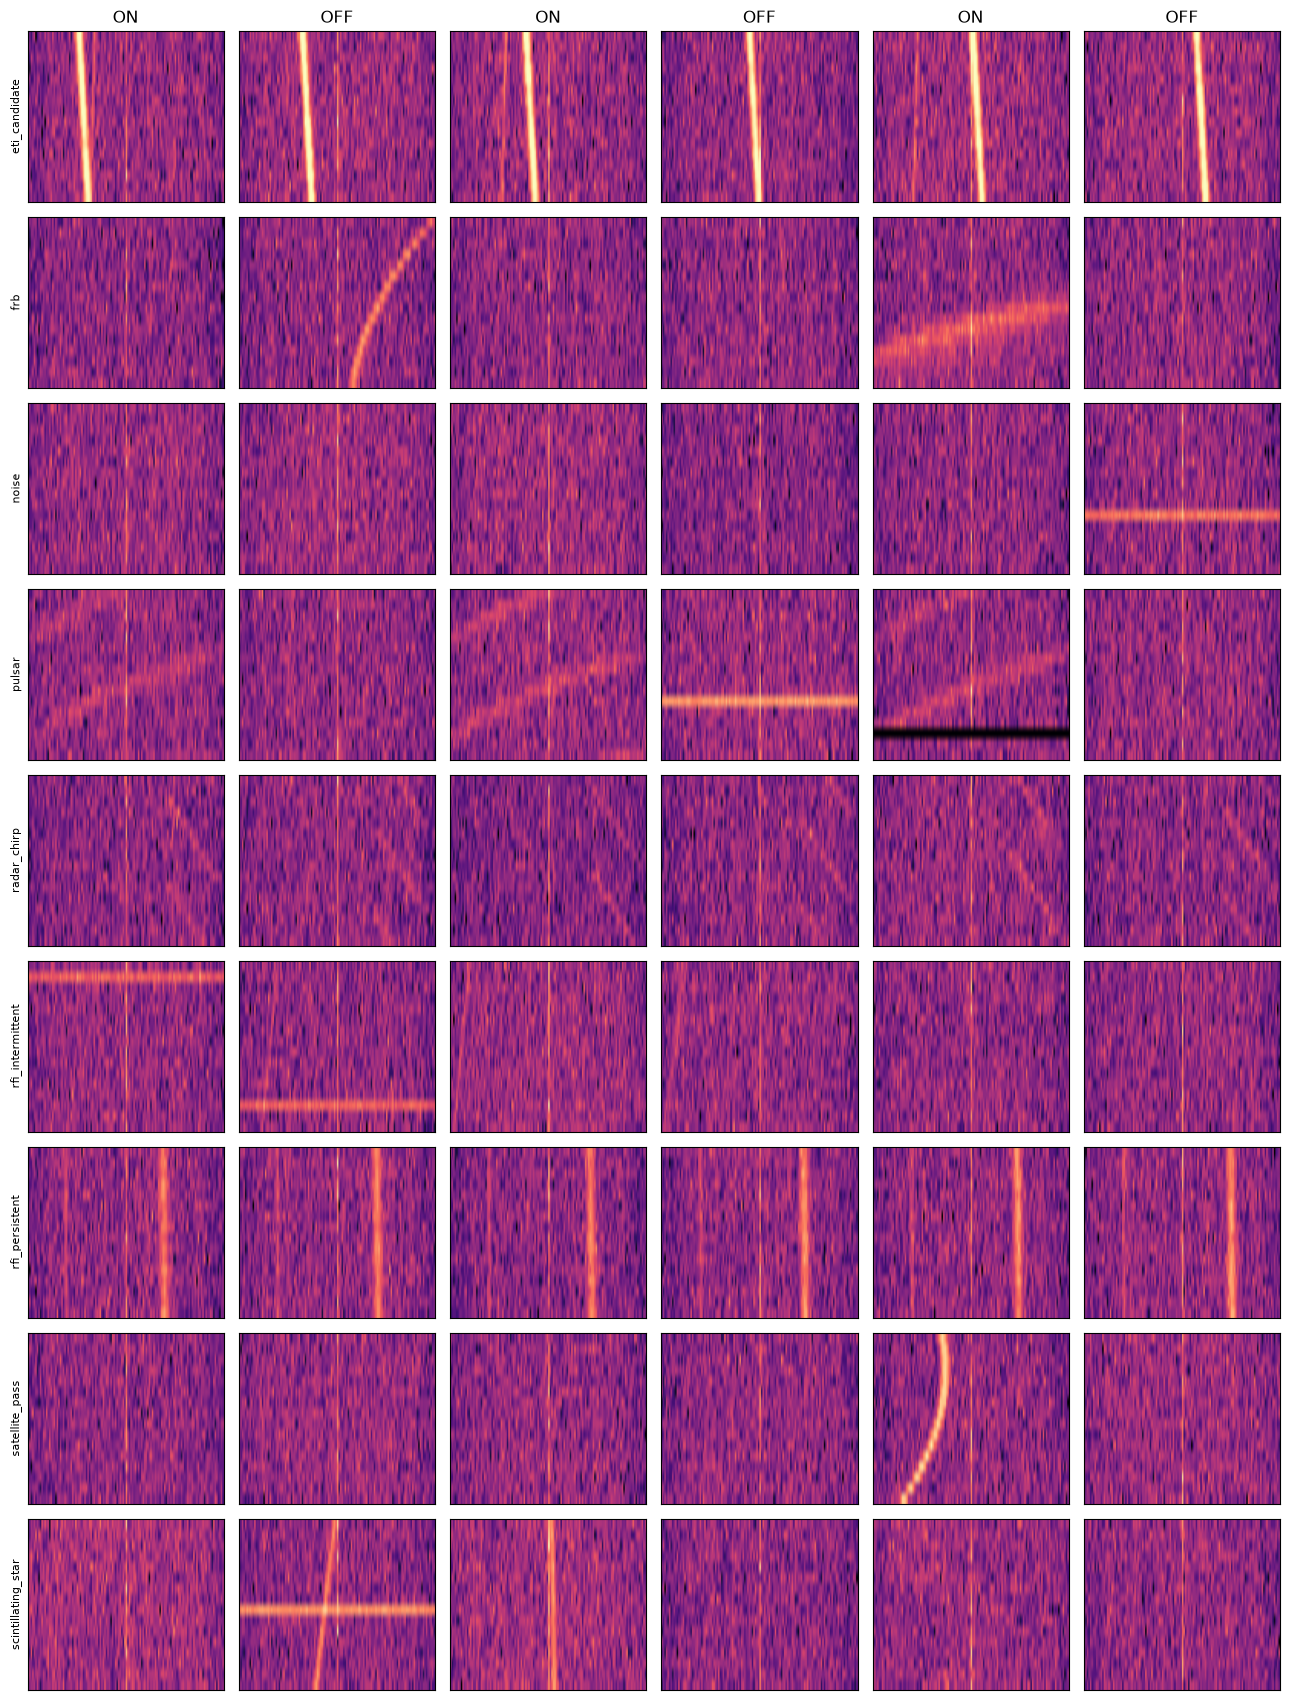

In [4]:
labels = sorted(train.label.unique())
fig, axes = plt.subplots(len(labels), 6, figsize=(13, 1.9 * len(labels)))
for r, lab in enumerate(labels):
    i = train.index[train.label == lab][0]
    for p in range(6):
        ax = axes[r, p]
        ax.imshow(X_train[i, p], aspect='auto', cmap='magma', vmin=40, vmax=170)
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0: ax.set_title(['ON', 'OFF'][p % 2])
    axes[r, 0].set_ylabel(lab, fontsize=8)
plt.tight_layout(); plt.show()

## Simple features
For each panel: overall level, spread, the brightest channel and how much it stands out. Then ON-minus-OFF differences, plus the observing metadata.

In [5]:
def features(X, meta, batch=2000):
    out = []
    for s in range(0, len(X), batch):
        x = X[s:s + batch].astype(np.float32)                 # (b, 6, 16, 128)
        x[x == 0] = np.nan                                      # dropped rows
        x = x - np.nanmedian(x, axis=(2, 3), keepdims=True)     # remove the level of each panel
        prof = np.nanmean(x, axis=2)                            # (b, 6, 128): time-averaged spectrum
        f = {}
        for p in range(6):
            f[f'p{p}_std'] = np.nanstd(x[:, p], axis=(1, 2))
            f[f'p{p}_max'] = np.nanmax(x[:, p], axis=(1, 2))
            f[f'p{p}_peak'] = np.nanmax(prof[:, p], axis=1)
            f[f'p{p}_peak_ch'] = np.nanargmax(prof[:, p], axis=1)
            f[f'p{p}_rowmax'] = np.nanmax(np.nanmean(x[:, p], axis=2), axis=1)   # broadband events
        df = pd.DataFrame(f)
        for k in ['std', 'max', 'peak', 'rowmax']:
            on = df[[f'p{p}_{k}' for p in (0, 2, 4)]].mean(1)
            off = df[[f'p{p}_{k}' for p in (1, 3, 5)]].mean(1)
            df[f'on_minus_off_{k}'] = on - off
        out.append(df)
    F = pd.concat(out, ignore_index=True)
    return pd.concat([F, meta[['slew_gap_rows', 'tsamp_s', 'channel_width_hz']].reset_index(drop=True)], axis=1)

F_train = features(X_train, train)
F_test = features(X_test, test)
F_train.shape

C:\Users\kasir\AppData\Local\Temp\ipykernel_17440\250054591.py:17: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  on = df[[f'p{p}_{k}' for p in (0, 2, 4)]].mean(1)
C:\Users\kasir\AppData\Local\Temp\ipykernel_17440\250054591.py:18: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  off = df[[f'p{p}_{k}' for p in (1, 3, 5)]].mean(1)


(18000, 37)

## Train and validate
Hold out 20% of the training cadences. (The test set comes from a different telescope, so expect your leaderboard score to be lower.)

In [18]:
X_tr, X_va, y_tr, y_va = train_test_split(F_train, train.label, test_size=0.2, stratify=train.label, random_state=42)
model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight='balanced', random_state=0)
model.fit(X_tr, y_tr)
print('validation macro-F1:', round(f1_score(y_va, model.predict(X_va), average='macro'), 4))

validation macro-F1: 0.5461


## Train on everything and write the submission

In [19]:
model.fit(F_train, train.label)
sub = pd.DataFrame({'id': test.id, 'label': model.predict(F_test)})
sub.to_csv('../outputs/submissions/submission.csv', index=False)
sub.label.value_counts()

label
rfi_persistent        8098
rfi_intermittent       916
pulsar                 387
frb                    300
eti_candidate          119
radar_chirp            112
satellite_pass          55
scintillating_star      13
Name: count, dtype: int64

## Ideas to climb the leaderboard
- **Flatten the bandpass** per channel, and normalise each cadence so the PKS test data looks like the GBT training data.
- **Drift search**: for every panel, find the straight line (start channel, drift rate) with the most summed power.
- **Cadence logic**: line in all 3 ON panels, none of the OFF panels, and the 3 ON positions fit one track in global time (`p × (16 + slew_gap_rows) + r`).
- **De-disperse**: shift each channel by a curved delay and sum, to find pulsars (repeating) and FRBs (one burst).
- **CNNs**: stack the 6 panels as input channels; or a siamese network comparing ON and OFF panels.
- **Augment**: frequency shifts, frequency flips (the drift sign flips too), small gain changes.